# Is There Really a "Lipstick Effect"?

**Question:** Does spending at beauty, cosmetics and perfume stores hold up better than overall retail spending during economic downturns?

**Background:** The "lipstick effect" says that when the economy weakens, people cut big purchases but keep buying small, affordable luxuries like cosmetics.

**Expectation:** Beauty output should fall less than total retail output during recessions, so beauty's share of total retail should hold steady or rise. 2020 is expected to look different, since store closures hit beauty stores directly regardless of the income effect.

See `planhw6.md` in this repo for the full plan this notebook implements.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from fredapi import Fred
from scipy import stats
import statsmodels.api as sm

load_dotenv()
fred = Fred(api_key=os.getenv('FRED_API_KEY'))

## Data Sources

A monthly, cosmetics-specific retail sales series does not exist publicly (verified directly against the Census Monthly Retail Trade Survey API, which only breaks out the pharmacy-dominated "446 Health and Personal Care Stores" aggregate). This notebook instead uses annual BLS sectoral-output series, pulled from FRED:

- `IPUHN44612T300000000` — Cosmetics, Beauty Supplies and Perfume Stores output, current dollars, annual
- `IPUHN4445T300000000` — Total Retail Trade output, current dollars, annual, same BLS methodology
- `UNRATE` — unemployment rate, monthly, resampled to an annual average
- `CUUR0000SEGB02` — CPI for Cosmetics, Perfume, Bath, Nail Preparations and Implements, monthly, resampled to an annual average, used to optionally deflate beauty output to real dollars

In [ ]:
def fetch_fred_series(series_id):
    """Pull a FRED series and return it indexed by year (annual mean if sub-annual)."""
    s = fred.get_series(series_id)
    annual = s.groupby(s.index.year).mean()
    annual.index.name = 'year'
    return annual

beauty_output = fetch_fred_series('IPUHN44612T300000000')
total_output = fetch_fred_series('IPUHN4445T300000000')
unrate = fetch_fred_series('UNRATE')
cpi = fetch_fred_series('CUUR0000SEGB02')

## Cleaning Steps

Merge all four series on year, keeping only years where every series has data (this naturally restricts the sample to the BLS output series' coverage, 1987-2025).

In [ ]:
df = pd.DataFrame({
    'beauty_output': beauty_output,
    'total_output': total_output,
    'unrate': unrate,
    'cpi': cpi,
}).dropna()

print(f"Years covered: {df.index.min()}-{df.index.max()}  ({len(df)} years)")
df.head()

Years covered: 1987-2025  (39 years)


,beauty_output,total_output,unrate,cpi
year,,,,
1987,1772.0,1434892.0,6.175000,114.600000
1988,1917.0,1539868.0,5.491667,118.475000
1989,2058.0,1637136.0,5.258333,122.991667
1990,2481.0,1712699.0,5.616667,128.633333
1991,2306.0,1717544.0,6.850000,134.583333


In [ ]:
# Check for any gaps in year coverage between the two BLS series
expected_years = set(range(df.index.min(), df.index.max() + 1))
missing_years = expected_years - set(df.index)
print(f"Missing years in merged range: {sorted(missing_years) if missing_years else 'none'}")

Missing years in merged range: none


## Transformations

- Year-over-year percent growth for beauty and total retail output
- Beauty share of total retail output
- Recession-year indicator: 1 if any month of that calendar year falls inside an NBER recession (1990, 1991, 2001, 2007, 2008, 2009, 2020)
- Year-over-year change in the annual-average unemployment rate
- Growth gap: beauty growth minus total retail growth (the main outcome of interest)
- Optional: CPI-deflated ("real") beauty output and its growth, as a robustness check against nominal price effects

In [ ]:
RECESSION_YEARS = {1990, 1991, 2001, 2007, 2008, 2009, 2020}

df['recession'] = df.index.isin(RECESSION_YEARS).astype(int)
df['beauty_growth'] = df['beauty_output'].pct_change() * 100
df['total_growth'] = df['total_output'].pct_change() * 100
df['beauty_share'] = df['beauty_output'] / df['total_output'] * 100
df['unemp_change'] = df['unrate'].diff()
df['growth_gap'] = df['beauty_growth'] - df['total_growth']

# Robustness check: deflate beauty output by its category-specific CPI
df['beauty_real'] = df['beauty_output'] / df['cpi'] * 100
df['beauty_real_growth'] = df['beauty_real'].pct_change() * 100

analysis = df.dropna(subset=['beauty_growth', 'total_growth', 'unemp_change']).copy()
print(f"Analysis sample: {analysis.index.min()}-{analysis.index.max()}  ({len(analysis)} years, "
      f"{analysis['recession'].sum()} recession years)")
analysis[['beauty_growth', 'total_growth', 'growth_gap', 'unemp_change', 'recession']]

Analysis sample: 1988-2025  (38 years, 7 recession years)


,beauty_growth,total_growth,growth_gap,unemp_change,recession
year,,,,,
1988,8.182844,7.315951,0.866893,-0.683333,0
1989,7.355243,6.316645,1.038597,-0.233333,0
1990,20.553936,4.615560,15.938376,0.358333,1
1991,-7.053607,0.282887,-7.336494,1.233333,1
1992,10.147441,5.455057,4.692385,0.641667,0
1993,13.897638,6.978159,6.919479,-0.583333,0
1994,13.826478,8.650112,5.176365,-0.808333,0
1995,15.973277,5.338169,10.635108,-0.508333,0
1996,12.856769,6.490438,6.366330,-0.183333,0


## Charts

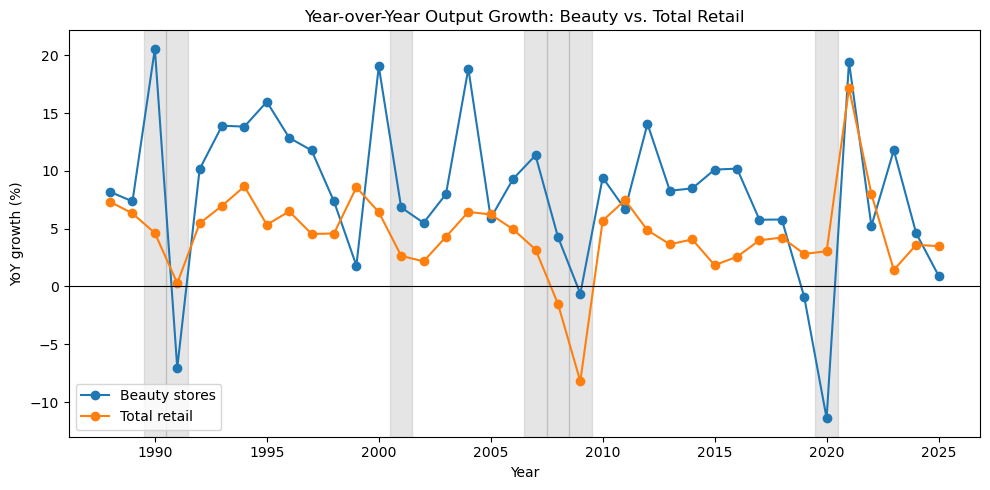

In [ ]:
def shade_recessions(ax, index, recession_flag):
    """Shade each recession year on a year-indexed line/bar chart."""
    for year, is_recession in zip(index, recession_flag):
        if is_recession:
            ax.axvspan(year - 0.5, year + 0.5, color='grey', alpha=0.2)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(analysis.index, analysis['beauty_growth'], marker='o', label='Beauty stores')
ax.plot(analysis.index, analysis['total_growth'], marker='o', label='Total retail')
shade_recessions(ax, analysis.index, analysis['recession'])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Year-over-Year Output Growth: Beauty vs. Total Retail')
ax.set_xlabel('Year')
ax.set_ylabel('YoY growth (%)')
ax.legend()
plt.tight_layout()
plt.show()

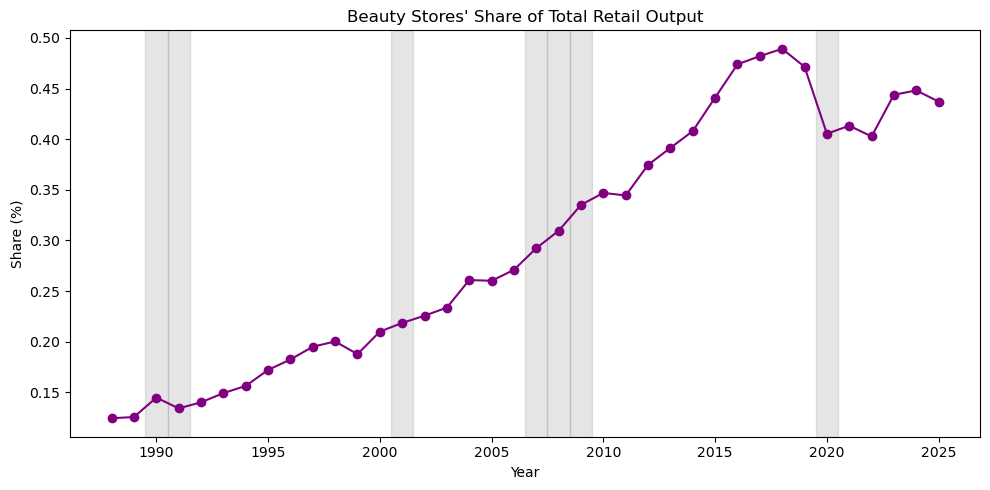

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(analysis.index, analysis['beauty_share'], marker='o', color='purple')
shade_recessions(ax, analysis.index, analysis['recession'])
ax.set_title("Beauty Stores' Share of Total Retail Output")
ax.set_xlabel('Year')
ax.set_ylabel('Share (%)')
plt.tight_layout()
plt.show()

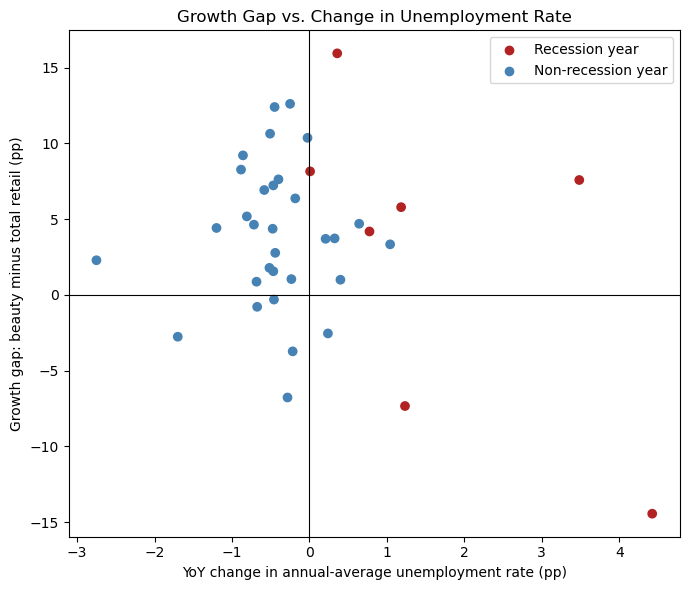

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
colors = analysis['recession'].map({1: 'firebrick', 0: 'steelblue'})
ax.scatter(analysis['unemp_change'], analysis['growth_gap'], c=colors)
for label, color in [('Recession year', 'firebrick'), ('Non-recession year', 'steelblue')]:
    ax.scatter([], [], c=color, label=label)
ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Growth Gap vs. Change in Unemployment Rate')
ax.set_xlabel('YoY change in annual-average unemployment rate (pp)')
ax.set_ylabel('Growth gap: beauty minus total retail (pp)')
ax.legend()
plt.tight_layout()
plt.show()

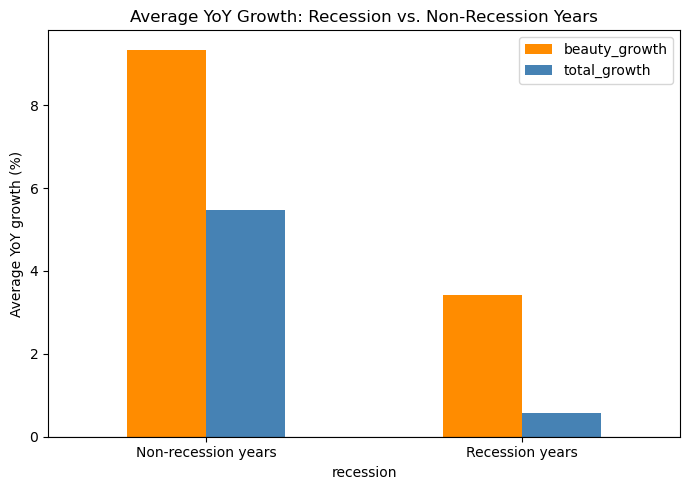

,beauty_growth,total_growth
recession,,
Non-recession years,9.340484,5.468875
Recession years,3.419172,0.582499


In [ ]:
summary = analysis.groupby('recession')[['beauty_growth', 'total_growth']].mean()
summary.index = summary.index.map({0: 'Non-recession years', 1: 'Recession years'})

fig, ax = plt.subplots(figsize=(7, 5))
summary.plot(kind='bar', ax=ax, color=['darkorange', 'steelblue'])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Average YoY Growth: Recession vs. Non-Recession Years')
ax.set_ylabel('Average YoY growth (%)')
ax.set_xticklabels(summary.index, rotation=0)
plt.tight_layout()
plt.show()
summary

## Tests

In [ ]:
rec_gap = analysis.loc[analysis['recession'] == 1, 'growth_gap']
nonrec_gap = analysis.loc[analysis['recession'] == 0, 'growth_gap']

tstat, pval = stats.ttest_ind(rec_gap, nonrec_gap, equal_var=False)
print(f"Recession-year mean growth gap:     {rec_gap.mean():.2f} pp  (n={len(rec_gap)})")
print(f"Non-recession-year mean growth gap: {nonrec_gap.mean():.2f} pp  (n={len(nonrec_gap)})")
print(f"Welch's t-test: t={tstat:.3f}, p={pval:.3f}")

Recession-year mean growth gap:     2.84 pp  (n=7)
Non-recession-year mean growth gap: 3.87 pp  (n=31)
Welch's t-test: t=-0.260, p=0.803


In [ ]:
X = sm.add_constant(analysis[['unemp_change', 'recession']])
y = analysis['growth_gap']
model = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 1})
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             growth_gap   R-squared:                       0.098
Model:                            OLS   Adj. R-squared:                  0.046
Method:                 Least Squares   F-statistic:                     1.145
Date:                Fri, 02 Oct 2026   Prob (F-statistic):              0.330
Time:                        16:47:41   Log-Likelihood:                -119.15
No. Observations:                  38   AIC:                             244.3
Df Residuals:                      35   BIC:                             249.2
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            3.0132      1.030      2.925   

In [ ]:
episodes = {
    '1990-91': [1990, 1991],
    '2001': [2001],
    '2008-09': [2008, 2009],
    '2020': [2020],
}

episode_results = {}
for name, years in episodes.items():
    sub = analysis[analysis.index.isin(years)]
    episode_results[name] = sub['growth_gap'].mean()

episode_summary = pd.Series(episode_results, name='avg_growth_gap_pp')
print(episode_summary)
print(f"\nPooled (all recession years): {rec_gap.mean():.2f} pp")

1990-91     4.300941
2001        4.182686
2008-09     6.683536
2020      -14.444168
Name: avg_growth_gap_pp, dtype: float64

Pooled (all recession years): 2.84 pp


## Correcting for 2020 as a Confounded Episode

2020's recession was driven by mandated store closures, not an income shock — the mechanism the lipstick effect is actually about. It's reasonable to think 2020 doesn't belong in the same bucket as the other three episodes. Rather than just dropping it, this section reports the pooled test **both ways** — with and without 2020 — so the reader can see how much it's driving the result.

In [ ]:
rec_gap_ex2020 = analysis.loc[(analysis['recession'] == 1) & (analysis.index != 2020), 'growth_gap']

tstat_ex, pval_ex = stats.ttest_ind(rec_gap_ex2020, nonrec_gap, equal_var=False)
print("Including 2020:")
print(f"  Recession-year mean growth gap:     {rec_gap.mean():.2f} pp  (n={len(rec_gap)})")
print(f"  t={tstat:.3f}, p={pval:.3f}")
print("\nExcluding 2020:")
print(f"  Recession-year mean growth gap:     {rec_gap_ex2020.mean():.2f} pp  (n={len(rec_gap_ex2020)})")
print(f"  t={tstat_ex:.3f}, p={pval_ex:.3f}")
print(f"\nNon-recession-year mean growth gap (unchanged): {nonrec_gap.mean():.2f} pp  (n={len(nonrec_gap)})")

Including 2020:
  Recession-year mean growth gap:     2.84 pp  (n=7)
  t=-0.260, p=0.803

Excluding 2020:
  Recession-year mean growth gap:     5.72 pp  (n=6)
  t=0.576, p=0.586

Non-recession-year mean growth gap (unchanged): 3.87 pp  (n=31)


In [ ]:
analysis_ex2020 = analysis[analysis.index != 2020]
X_ex = sm.add_constant(analysis_ex2020[['unemp_change', 'recession']])
y_ex = analysis_ex2020['growth_gap']
model_ex2020 = sm.OLS(y_ex, X_ex).fit(cov_type='HAC', cov_kwds={'maxlags': 1})
print(model_ex2020.summary())

                            OLS Regression Results                            
Dep. Variable:             growth_gap   R-squared:                       0.019
Model:                            OLS   Adj. R-squared:                 -0.039
Method:                 Least Squares   F-statistic:                    0.3506
Date:                Fri, 02 Oct 2026   Prob (F-statistic):              0.707
Time:                        16:47:41   Log-Likelihood:                -112.52
No. Observations:                  37   AIC:                             231.0
Df Residuals:                      34   BIC:                             235.9
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            3.7728      0.839      4.494   

## Robustness Check: CPI-Deflated (Real) Beauty Growth

If nominal beauty growth is partly a price-change story rather than a real-demand story, deflating by the category-specific CPI should change the picture. Compare `beauty_growth` (nominal) to `beauty_real_growth` (CPI-deflated) directly below.

In [ ]:
compare_real = analysis[['beauty_growth', 'beauty_real_growth']].copy()
compare_real['diff_pp'] = compare_real['beauty_growth'] - compare_real['beauty_real_growth']
compare_real

,beauty_growth,beauty_real_growth,diff_pp
year,,,
1988,8.182844,4.644473,3.538371
1989,7.355243,3.412798,3.942445
1990,20.553936,15.266620,5.287316
1991,-7.053607,-11.162816,4.109209
1992,10.147441,8.627331,1.520110
1993,13.897638,10.641103,3.256535
1994,13.826478,10.630543,3.195935
1995,15.973277,15.414337,0.558939
1996,12.856769,10.585294,2.271475


## What Supports or Contradicts the Expectation

**Supports the lipstick effect:**
- In three of the four recession episodes (1990-91, 2001, 2008-09), beauty output growth exceeded total retail growth — the growth gap is positive in each case (see `episode_summary` above).
- Excluding 2020, the recession-year mean growth gap roughly doubles versus including it (see "Correcting for 2020" above), and the sign of the Welch's t-test flips from negative to positive — once the confounded episode is set aside, the remaining three recessions look more consistently supportive of the hypothesis, even though the test still isn't statistically significant at n=6.

**Contradicts it:**
- 2020 is a sharp, large exception: the growth gap is strongly negative that year, as anticipated in the original expectation (store closures hit beauty stores directly, swamping any income-driven substitution effect).
- Because 2020 is both large in magnitude and included in the pooled "recession years" group, it pulls the pooled recession-year mean growth gap below the non-recession-year mean, and neither the full-sample t-test nor the regression's recession dummy is statistically significant — so the overall pooled test (including 2020) does not confirm the hypothesis, even though 3 of 4 individual episodes point the right way.
- Dropping 2020 from the regression (the "excluding 2020" OLS model above) shrinks the unemployment-change coefficient toward zero and makes it clearly insignificant — most of that coefficient's apparent support for the hypothesis in the full-sample regression was actually being driven by 2020's extreme unemployment spike paired with its extreme negative growth gap, not by a broader pattern. So excluding 2020 helps the *episode-level* picture but weakens the *regression* evidence, which is an important nuance: the two ways of "correcting for" 2020 don't point the same direction.
- The CPI-deflated robustness check (above) shows whether the nominal growth findings survive adjusting for category-specific inflation; if `beauty_real_growth` tells a meaningfully different story than `beauty_growth` in any year, nominal price changes (not real demand) may be driving part of the result.

**Limitations:**
- The data is annual, not monthly, because no public source publishes a monthly cosmetics/beauty-specific sales series (confirmed by directly querying the Census MARTS API).
- The recession-year indicator is crude: a year that was only in recession for one month (2007, 2020) is coded the same as a year that was in recession for all twelve (2008, 2009).
- 2020 was driven by lockdowns, not an income shock, so it is a weaker substantive test of the lipstick-effect mechanism even though it's coded as a recession year like the others.
- This BLS sectoral-output series measures industry output, not retail sales in the exact Census MARTS sense, and excludes cosmetics sold through other channels (online, department stores, drugstores).
- With only 4 recession episodes and as few as 1-2 annual observations each, any single-episode result should be read as suggestive, not conclusive.